# Alignment quality of the unmasked chr22 databank alignments (custom sum-of-pairs score)

Sum-of-pairs score in non-overlapping windows of `WINDOW` columns (1 kb by default) of the per-fragment
Human/Chimpanzee/Orangutan alignments downloaded by `eti` for each region in `DATA_DIRS`
(`HumChimpOranGor_10_114/<region>/nonmaksed_alldata_chrm22`). Every `.fa` file at the top
level of the directory is read; subfolders (`logs/`, `md5/`, `not_completed/`) are ignored.
Windows are taken within each file, so none spans two fragments, and the scores of all files
are pooled into one distribution per region.

**Why a custom score.** cogent3's `sp_score` app (`cogent3==2026.9.10`) returns wrong values
whenever its distance calculator marks a sequence as a "duplicate", which happens for any pair
with no mismatching site: a species that is all gaps in the window, one with only a few
nucleotides that all agree with another species, or two genuinely identical sequences. See
`alignment_quality_test.ipynb` for the mechanism and minimal examples. `expected_sp_score`
below computes the same quantity directly from the sequences and is not affected:

- for each species pair, $L$ = number of sites where both have a nucleotide, $p$ = proportion
  of those sites that differ, $d$ = genetic distance (`JC69`: $-\tfrac34\ln(1-\tfrac43 p)$,
  `pdist`: $p$), similarity $= \max(L\,(1-d),\,0)$;
- minus an affine gap penalty for the gap runs present in only one of the two sequences
  (`gap_insert=12` per run, `gap_extend=1` per position), computed with cogent3's `gap_dist` app;
- summed over the three pairs.

With 3 sequences the maximum is 3 × `WINDOW` (three identical, gap-free sequences);
gap-dominated windows go strongly negative. A window where some pair has $p \ge 0.75$ has no
`JC69` distance; such windows get `nan`, are counted in `failed_windows` and excluded, exactly
as the cogent3 app's `NotCompleted` results were. `calc = "pdist"` never fails.

**Short fragments are not scored.** The trailing partial window of each file is dropped so
that every score covers the same number of columns, which means a file
shorter than `WINDOW`
contributes no windows. Compare `scored_length` with `n_windows × WINDOW` in the summary table
to see how much sequence this leaves out.

`frac_allgap_cols` reports the fraction of columns that are gaps in all three species. Such
columns contribute nothing to the score, so with `DROP_ALLGAP_COLUMNS = True` they are removed
with `omit_gap_pos()` before windowing and every window then holds `WINDOW` scorable columns.
The databank alignments should contain few or none of them.

The figure is written to `FIG_DIR` with the window size in its name, so runs with different
`WINDOW` values do not overwrite each other.

In [1]:
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cogent3 import load_aligned_seqs, make_aligned_seqs, get_app

ModuleNotFoundError: No module named 'pandas'

In [ ]:
# region label -> directory of per-fragment .fa alignments (top level only; subfolders ignored)
DATA_DIRS = {
    "intergenicAR": "/xdisk/masel/uliseshmc/EstimatingUd/HumChimpOranGor_10_114/intergenicAR/nonmaksed_alldata_chrm22",
    "distalIG": "/xdisk/masel/uliseshmc/EstimatingUd/HumChimpOranGor_10_114/distalIG/nonmaksed_alldata_chrm22",
}
REGIONS = list(DATA_DIRS)
WINDOW = 50  # columns per window
# window size for labels and file names: "1kb", "2kb", ... for multiples of 1000, otherwise e.g. "500bp"
WINDOW_TAG = f"{WINDOW // 1000}kb" if WINDOW % 1000 == 0 else f"{WINDOW}bp"
FIG_DIR = Path("output_data/alignment_quality")  # created if missing

DROP_ALLGAP_COLUMNS = False  # remove columns that are '-' in every species before windowing

# score settings (same as cogent3's sp_score defaults); calc="pdist" never gives nan
CALC = "JC69"
GAP_INSERT, GAP_EXTEND = 12.0, 1.0
BASES = list("ACGT")
gap_penalty = get_app("gap_dist", gap_insert=GAP_INSERT, gap_extend=GAP_EXTEND)

In [ ]:
def expected_sp_score(aln, calc=CALC):
    """Sum-of-pairs score of an alignment, computed directly from the sequences.

    Replaces cogent3's ``sp_score`` app, which mis-scores alignments in which its
    distance calculator marks a sequence as a duplicate (see
    alignment_quality_test.ipynb). Returns nan when the score is undefined:
    fewer than two sequences, zero length, or (``JC69`` only) a pair with a
    proportion of differences >= 0.75.
    """
    if aln.num_seqs < 2 or len(aln) == 0:
        return np.nan
    arr = {n: np.array(list(str(aln.seqs[n]))) for n in aln.names}
    gaps = gap_penalty(aln)
    total = 0.0
    for a, b in combinations(aln.names, 2):
        both = np.isin(arr[a], BASES) & np.isin(arr[b], BASES)
        length = int(both.sum())
        if length:
            p = (arr[a][both] != arr[b][both]).mean()
            if calc == "pdist":
                d = p
            elif calc == "JC69":
                if p >= 0.75:
                    return np.nan
                d = -0.75 * np.log(1 - 4 * p / 3)
            else:
                raise ValueError(f"unsupported calc {calc!r}; use 'JC69' or 'pdist'")
            total += max(length * (1 - d), 0.0)
        total -= gaps[a, b]
    return total


def window_sp_scores(aln, window, score=expected_sp_score):
    """score for each non-overlapping window of `window` columns.

    The trailing partial window is dropped so every score is on the same
    number of columns. Windows whose score is undefined (nan) are counted
    and excluded.
    """
    scores, failed = [], 0
    for start in range(0, len(aln) - window + 1, window):
        value = score(aln[start : start + window])
        if np.isfinite(value):
            scores.append(value)
        else:
            failed += 1
    return np.array(scores), failed

In [ ]:
scores = {}
summary = []
for region in REGIONS:
    # Path.glob("*.fa") is not recursive, so files in logs/, md5/, not_completed/ are skipped
    fnames = sorted(p for p in Path(DATA_DIRS[region]).glob("*.fa") if p.is_file())
    region_scores, failed, file_length, allgap_cols, scored_length = [], 0, 0, 0, 0
    for fname in fnames:
        raw = load_aligned_seqs(fname, moltype="dna")
        nogap = raw.omit_gap_pos()
        aln = nogap if DROP_ALLGAP_COLUMNS else raw
        # windows are taken per file so none spans two alignment fragments
        s, f = window_sp_scores(aln, WINDOW)
        region_scores.append(s)
        failed += f
        file_length += len(raw)
        allgap_cols += len(raw) - len(nogap)
        scored_length += len(aln)
    scores[region] = s = np.concatenate(region_scores)
    summary.append(
        {
            "region": region,
            "n_files": len(fnames),
            "file_length": file_length,
            "frac_allgap_cols": allgap_cols / file_length,
            "scored_length": scored_length,
            "n_windows": len(s),
            "failed_windows": failed,
            "mean": s.mean(),
            "median": np.median(s),
            "q05": np.quantile(s, 0.05),
            "q95": np.quantile(s, 0.95),
            "frac_negative": (s < 0).mean(),
        }
    )

summary = pd.DataFrame(summary).set_index("region")
summary

,n_files,file_length,frac_allgap_cols,scored_length,n_windows,failed_windows,mean,median,q05,q95,frac_negative
region,,,,,,,,,,,
intergenicAR,551,3495406,0.0,3495406,69618,28,55.992398,139.451599,-124.0,150.0,0.313382
distalIG,185,1155301,0.0,1155301,23010,1,101.433312,143.804306,-124.0,150.0,0.144242


The regions differ ~3x in length, so the histograms are drawn as densities on a shared set of
bins; otherwise the longer region would swamp the other.

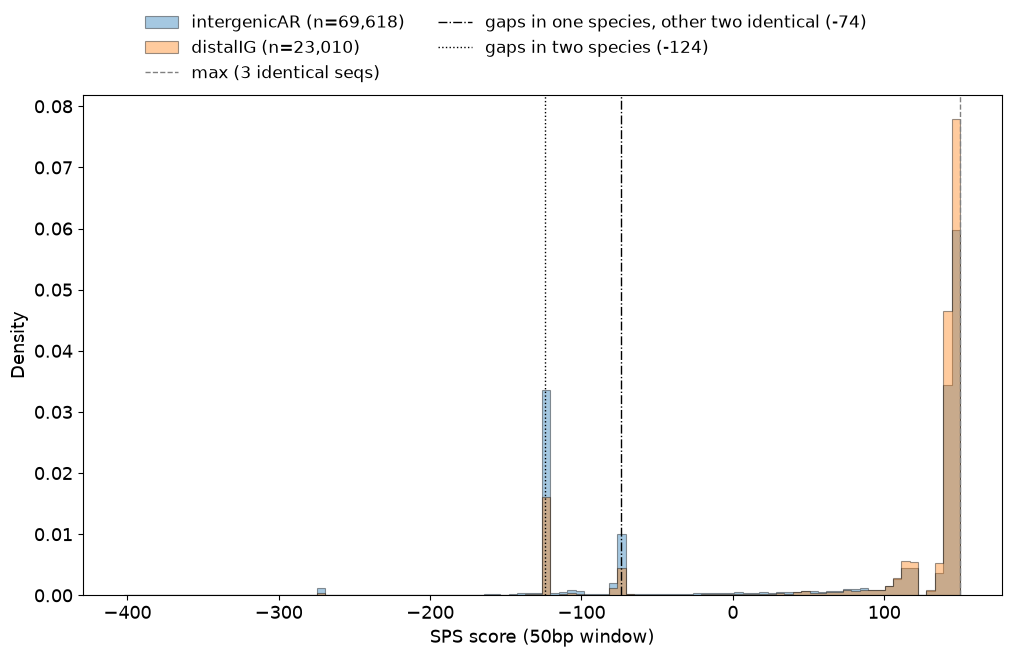

In [ ]:
all_scores = np.concatenate(list(scores.values()))
bins = np.linspace(all_scores.min(), all_scores.max(), 101)

# reference scores for two extreme windows, computed with the same function:
# one species entirely gaps while the other two are identical: WINDOW - 2 (12 + WINDOW)
# two species entirely gaps (they share the same gap run): -2 (12 + WINDOW)


full, empty = "A" * WINDOW, "-" * WINDOW
reference_scores = {
    "gaps in one species, other two identical": expected_sp_score(
        make_aligned_seqs({"a": full, "b": full, "c": empty}, moltype="dna")
    ),
        "gaps in two species": expected_sp_score(
        make_aligned_seqs({"a": full, "b": empty, "c": empty}, moltype="dna")
    ),
    
}

# fixed font sizes; setting them (rather than adding to the current size) keeps the
# figure identical however many times this cell is run
FONT_SIZE = 13
plt.rcParams.update(
    {key: FONT_SIZE for key in ("font.size", "axes.labelsize", "xtick.labelsize", "ytick.labelsize")}
)
plt.rcParams["legend.fontsize"] = FONT_SIZE - 1

# constrained layout gives the legend its own space above the axes, so the plot keeps its size
fig, ax = plt.subplots(figsize=(10, 6.5), layout="constrained")
for region in REGIONS:
    ax.hist(
        scores[region],
        bins=bins,
        density=True,
        histtype="stepfilled",
        alpha=0.4,
        edgecolor="black",
        linewidth=0.8,
        label=f"{region} (n={len(scores[region]):,})",
    )
ax.axvline(3 * WINDOW, color="grey", linestyle="--", linewidth=1, label="max (3 identical seqs)")
for (label, value), style in zip(reference_scores.items(), ("-.", ":")):
    ax.axvline(value, color="black", linestyle=style, linewidth=1, label=f"{label} ({value:.0f})")
ax.set_xlabel(f"SPS score ({WINDOW_TAG} window)")
ax.set_ylabel("Density")
# legend above the plot, outside the axes
fig.legend(loc="outside upper center", ncol=2, frameon=False)
FIG_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIG_DIR / f"alignment_quality_customsp_score_{WINDOW_TAG}.png", dpi=150)
plt.show()